# 00 · Learning to reason with data

Statistics connects a question about the world to a conclusion that acknowledges uncertainty. A calculation becomes useful only after we know what was measured, how the observations were obtained, and which claim we want to assess.

```mermaid
flowchart LR
    Q[Question and target population] --> D[Design and collect]
    D --> E[Explore variation]
    E --> M[Model and estimate]
    M --> U[Quantify uncertainty]
    U --> A[Decide and communicate]
    A --> Q
```

**Learning route:** question → design → description → inference → decision. Read [the prerequisites](../AA_Prerequisite/AA_Prerequisite.md) whenever notation or Python gets in the way. This chapter needs only arithmetic.

## 1. Start with a question you can measure

Suppose a library is considering two ways to return borrowed equipment. Is a staffed desk or a self-service kiosk faster? “Better” is not yet a statistical question. Better might mean shorter average time, fewer very long waits, fewer errors, or lower cost. Each requires a different outcome.

We choose **elapsed return time in minutes** and ask about eligible weekday returns at this library during the next term. A row represents one return, with a method, date, and elapsed time. Define the timer's start and stop before collecting data. Counting time only after a user reaches the desk would answer a different question from counting time since joining the queue.

A **population** is the set of units or outcomes our question concerns. A **sample** is the observed subset. A **parameter** is a numerical feature of the population or probability model. A **statistic** is a function of the observed sample. Our target, or **estimand**, is

$$\Delta=\mu_{\mathrm{kiosk}}-\mu_{\mathrm{desk}}.$$

Negative values mean a faster kiosk on average. Writing this sign convention now prevents reversing the conclusion later. It also distinguishes a population comparison from the observed difference between two sample means.

## 2. Four tasks that sound similar but are different

| Task | Example question | What it needs |
|---|---|---|
| Description | What were the observed return times? | Clear summaries and graphs |
| Estimation | What is the average difference in the target population? | A suitable design and uncertainty estimate |
| Prediction | How long will the next return take? | A model that works for future returns |
| Causal inference | What would change if we assigned the same eligible users to the other method? | A design or justified assumptions identifying that intervention |

A fitted line can predict well without identifying a cause. Users who choose a kiosk may already be comfortable with the equipment. A comparison of volunteers would mix a method difference with a user difference. Random assignment helps make treatment groups comparable in expectation. Random sampling serves a different purpose: supporting generalization to the target population. Neither guarantees perfect balance or perfect measurements in a particular study.

## 3. A first complete example

Consider these **invented** return times. They are small enough to calculate by hand and are not evidence about an actual library.

| Method | Times, in minutes | Mean |
|---|---|---:|
| Desk | 6, 8, 7, 9, 10 | 8 |
| Kiosk | 5, 7, 6, 8, 9 | 7 |

The estimated difference is $7-8=-1$ minute. This is a descriptive fact about these ten observations. It does not tell us whether another sample would show the same difference, nor whether the sampling process represents next term's users.

![Individual return times and means](figure/return_times.png)

The dots show the data that the means conceal: the groups overlap substantially. Overlap alone is not a hypothesis test. Equally, distinct sample averages alone are not proof of a population difference. Later chapters compare the estimated difference to its sampling uncertainty.

**Notebook experiment:** calculate the two means, then replace just the last kiosk time by 20. Predict how the mean changes before running the cell. Which observation causes the change, and would the median react as much?

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '00_Intro' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


Desk mean: 8.0; kiosk mean: 7.0
Kiosk - desk: -1.0 minutes


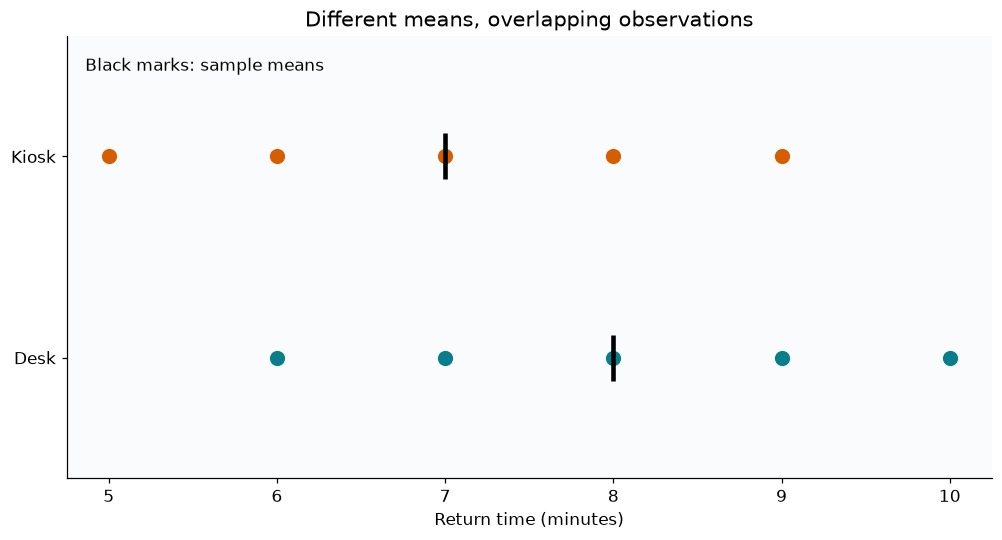

After replacing 9 by 20: mean=9.2, median=7.0


In [2]:
desk = np.array([6, 8, 7, 9, 10], dtype=float)
kiosk = np.array([5, 7, 6, 8, 9], dtype=float)
print(f"Desk mean: {desk.mean():.1f}; kiosk mean: {kiosk.mean():.1f}")
print(f"Kiosk - desk: {kiosk.mean() - desk.mean():.1f} minutes")
fig, ax = plt.subplots(layout="constrained")
for i, (name, values, color) in enumerate([("Desk", desk, TEAL), ("Kiosk", kiosk, ORANGE)]):
    ax.scatter(values, np.full(len(values), i), s=80, color=color, label=f"{name}: observations")
    ax.plot(values.mean(), i, marker="|", ms=30, mew=3, color="black")
ax.set(yticks=[0, 1], yticklabels=["Desk", "Kiosk"], ylim=(-.6, 1.6),
       xlabel="Return time (minutes)", title="Different means, overlapping observations")
ax.text(.02, .95, "Black marks: sample means", transform=ax.transAxes, va="top")
save_figure(fig, "return_times")
changed = kiosk.copy()
changed[-1] = 20
print(f"After replacing 9 by 20: mean={changed.mean():.1f}, median={np.median(changed):.1f}")

## 4. Why repeated samples disagree

Imagine that we could repeatedly sample five desk returns and five kiosk returns from stable processes. Each repetition produces different observations and therefore a different estimated difference. The distribution of those estimates is a **sampling distribution**.

The next simulation assumes two normal populations with means 8 and 7 minutes and a common standard deviation of 2 minutes. These are known inputs to a teaching simulation, not estimates justified by the ten numbers above. Samples are independent. The simulated estimand is exactly $-1$ minute, yet some estimated differences are positive.

![Sampling distributions of the estimated difference](figure/sampling_difference.png)

Compare five observations per group with fifty. Larger independent samples make the estimate more stable around the truth. They do not remove the variability of individual returns. They also cannot repair systematically selecting only fast kiosk users. That is **bias**, a different problem from sampling variability.

**Read the plot:** the dashed line marks the known population difference. The horizontal axis is an estimated difference, not an individual return time. The density axis is scaled so each histogram's area is one. Increasing sample size concentrates the estimates near the dashed line.

n=5: mean estimate -0.958, SD of estimates 1.253
n=50: mean estimate -0.997, SD of estimates 0.398


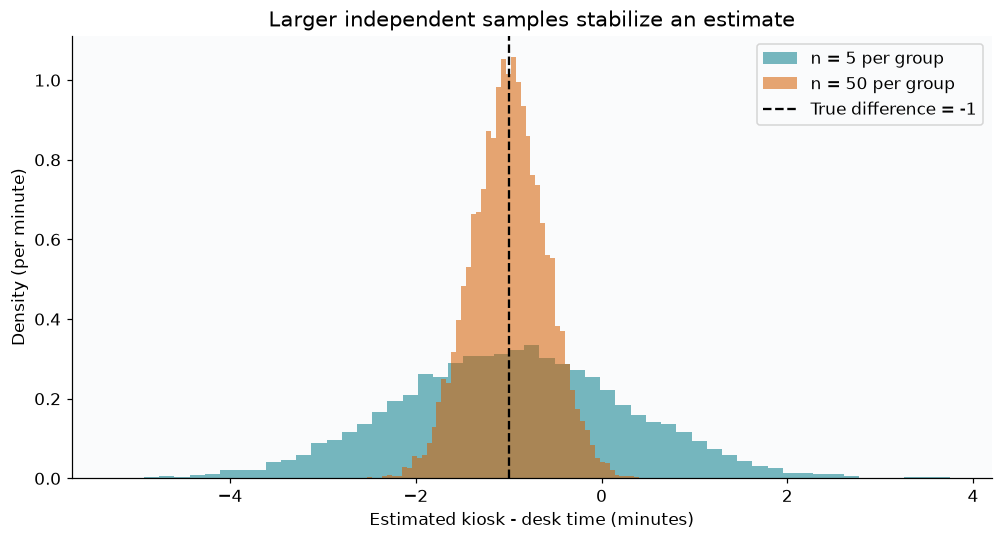

In [3]:
rng = np.random.default_rng(100)
fig, ax = plt.subplots(layout="constrained")
for n in [5, 50]:
    differences = (rng.normal(7, 2, (8000, n)).mean(axis=1)
                   - rng.normal(8, 2, (8000, n)).mean(axis=1))
    ax.hist(differences, bins=55, density=True, alpha=.55, label=f"n = {n} per group")
    print(f"n={n}: mean estimate {differences.mean():.3f}, SD of estimates {differences.std():.3f}")
ax.axvline(-1, color="black", ls="--", label="True difference = -1")
ax.set(xlabel="Estimated kiosk - desk time (minutes)", ylabel="Density (per minute)",
       title="Larger independent samples stabilize an estimate")
ax.legend()
save_figure(fig, "sampling_difference")

## 5. A useful statistical workflow

1. **Specify the claim.** Name the outcome, units, population, comparison, and time period. State which effect size would matter in practice.
2. **Design the study.** Identify the independent observational unit. Plan sampling, assignment, missing-data handling, and sample size.
3. **Look at the observations.** Check units, duplicates, missing values, unusual points, and plots before fitting models.
4. **Estimate and quantify uncertainty.** Report an effect in meaningful units and an interval, with assumptions made explicit.
5. **Check the analysis.** Ask whether clustering, nonlinear patterns, unusual observations, or multiple analyses change the interpretation.
6. **Communicate the scope.** State what the evidence supports, what remains uncertain, and what additional data would help.

An analysis is reproducible when someone else can obtain the same computational results from the recorded inputs and steps. Reproducibility does not establish that the design answers the scientific question. The notebooks make calculations reproducible; the explanatory notes teach how to evaluate their relevance.

## 6. How to use this repository

Read a section, predict what its graph or calculation should show, then run the corresponding notebook cells. Change one input at a time. Explain the changed result in a sentence before moving on. For simulations, compare a numerical result with its theoretical benchmark; a fixed random seed makes an experiment repeatable but does not make its assumptions true.

Every chapter has `<folder_name>.md`, `<folder_name>.ipynb`, and a `figure/` directory. Notebooks repeat the notes and interleave executable experiments. The figures are original and generated by the notebook code. Mermaid diagrams summarize the route through a chapter; the prose also gives that route because not every notebook viewer renders Mermaid.

The chapter sequence follows broad topics in Josh Starmer's book. Explanations, datasets, exercises, and graphics are independently written. Formal definitions and additional safeguards are included where intuition alone can mislead. The private book files are not needed to run the course. See [References](../Reference.md) for attribution and [publication guidance](../PUBLICATION.md) for source handling.

## 7. Practice

Try these before reading the answers.

1. An archive records the time needed for **every one of today's 40 returns**. Is its mean a population mean or a sample mean?
2. A second library observes locker-return times of 3, 4, 5, 8 minutes and desk times of 5, 6, 7, 10 minutes. Calculate locker minus desk. Can you conclude that lockers cause faster returns?
3. An analyst collects 50,000 records from users who volunteered to try a kiosk. What does the large sample solve, and what does it leave unresolved?
4. Why is predicting the next return generally harder than estimating a mean return time?

## 8. Worked answers

1. For today's 40 returns, it is a population mean. For next month's returns or a continuing return process, it is a sample-based estimate. The target determines the label.
2. The means are $20/4=5$ and $28/4=7$, so the observed difference is $-2$ minutes. Without information about assignment and comparability, this is an association, not an established causal effect.
3. More independent records can reduce sampling variability within the sampled process. They do not guarantee that volunteers represent nonvolunteers, fix measurement errors, or remove confounding.
4. A future individual has its own variability in addition to uncertainty about the average. Averaging many observations can reduce uncertainty about a mean, but it cannot make every individual identical.

In [4]:
locker = np.array([3, 4, 5, 8])
other_desk = np.array([5, 6, 7, 10])
assert locker.mean() - other_desk.mean() == -2
print("Practice 2: locker - desk =", locker.mean() - other_desk.mean(), "minutes")

Practice 2: locker - desk = -2.0 minutes


## References and next step

Reading connection: Starmer, *The StatQuest Illustrated Guide to Statistics* (2026), front matter and Chapter 1. See [SQ in the reference list](../Reference.md#sq-statquest). The example and workflow here are original teaching material.

Next: [01 · Fundamental concepts](../01_Fundamental_Concepts_in_Statistics/01_Fundamental_Concepts_in_Statistics.md).